In [167]:
from scipy.signal import find_peaks, savgol_filter
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

from brokenaxes import brokenaxes

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

import import_ipynb
import ipynb.fs.full.ssiProjectModule2 as ssiMod

import sys

from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect
from matplotlib.patches import Arc,FancyArrowPatch


output_dir = '/home/cparis/00PhD/DS_PCBreview/'



theta_step = 2
main_dir = '/home/cparis/00PhD/'

area_or_max = 'Area'
dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
print(data_dict.keys())


stim = np.arange(0,360,theta_step)

example = 201
bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
example_quad_pars = data_dict['all_quad_pars'][example,bio_idx]
example_quad_tc = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in example_quad_pars])

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])


In [242]:
def ellipse_slope_in_xy(x,y,Rx,Ry):
    if Rx==0:
        return -np.inf*np.sign(y)  #case where ellipse is collapsed onto a segment [-Ry, Ry]
    elif y==0:
        return -np.sign(x)*np.inf
    else:
        return -(x/y)*(Ry/Rx)**2 
    
def flow_ellipse_axis(x,y, Ry=1):
#     returns the minor ellipse axis along the x axis
    if y==Ry:
        return Ry/2  #arbitrary value
    else:
        return x/np.sqrt(1.-(y/Ry)**2)

def flow_in_point_of_ellipse(x,z, x_ax, z_ax, flow_parallel_comp, which, delta_arc = np.deg2rad(15), R=1):
#     NOTE: MODIFICATION OF LENGTH:
#           Consider 2 arrows at same source point, one pointing towards a pole, other pointing away from it
#           The arrow pointing towards will appear shorter when projected because of sphere curvature
#           This is coded in "np.sign(phi*x)*delta_arc" term
    lmbda = np.arctan(z/x) if x!=0 else -np.sign(z)*np.pi
    phi = np.arccos(np.sqrt(x**2+z**2)/R)
    slope_h = ellipse_slope_in_xy(x,z, x_ax, z_ax)
    if np.abs(slope_h)!=np.inf:
        new_theta = np.arctan(slope_h)+(1+np.sign(flow_parallel_comp*x*z))*np.pi/2*np.abs(np.sign(flow_parallel_comp))
        if which=='h':
            new_theta = -new_theta+np.pi/2
    elif np.abs(slope_h)==np.inf and which=='h': 
        new_theta = np.pi/2 - np.pi/2*np.sign(flow_parallel_comp)
#         new_theta = np.pi/2*np.sign(flow_parallel_comp)

    elif np.abs(slope_h)==np.inf and which=='v': 
        new_theta = np.pi/2*np.sign(flow_parallel_comp)
        
    amplitude_mod = np.sqrt(1.-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2\
                            *np.sin(lmbda+np.sign(flow_parallel_comp*x)*delta_arc)**2) 

#     if which=='v':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2)        
#     elif which=='h':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2) 
    return np.abs(flow_parallel_comp)*amplitude_mod, np.rad2deg(new_theta)
    
def direction_deformation(vector, x0,z0, R=1, arrow_len=0.15):
    vert_b, vert_a = R, flow_ellipse_axis(x0,z0)
    hor_a, hor_b = R, flow_ellipse_axis(z0,x0)
    final_arr = np.array([])
    for theta in np.deg2rad(vector):

        l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
        l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')

        resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
        final_arr = np.append(final_arr, resultant)

    final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

#     print(final_th.shape)
    new_vector = final_l*np.exp(1j*np.deg2rad(final_th))
    return final_l, final_th, new_vector

def eccentric_prior(x0,z0, stim_step = 2):
    stim = np.arange(0,360,stim_step)
    fine_stim = np.arange(0,360,stim_step/10)
    
    unif_prior = np.ones_like(stim)/(np.ones_like(stim)*stim_step).sum()
    _,final_theta,_ = direction_deformation(fine_stim, x0,z0)
    roll_idx = final_theta.argmin()
    d_xi = np.roll(np.abs(180-np.abs(180-np.abs((np.roll(np.roll(final_theta, -roll_idx), -1) \
                                          - np.roll(np.roll(final_theta, -roll_idx), 1)))))/2, roll_idx)

    xi_stim = np.roll(final_theta, -roll_idx).reshape(-1,int(fine_stim.size/stim.size)).mean(axis=1)
    avg_d_xi = np.gradient(xi_stim)/stim_step
    xi_prior = unif_prior/avg_d_xi
    return xi_stim, avg_d_xi, xi_prior

def plot_circle(ax, angle_deg, R=1.0, theta1=0, theta2=90):

    theta = np.deg2rad(angle_deg)

    x = R * np.cos(theta)
    y = R * np.sin(theta)

    # Draw only first quadrant arc
    arc = Arc((0, 0), 2*R, 2*R, theta1=theta1, theta2=theta2)
    ax.add_patch(arc)

    # Formatting
    ax.set_aspect('equal', adjustable='datalim')

    # restrict axes to first quadrant
    ax.set_xlim(-0.1*R, 1.1*R)
    ax.set_ylim(-0.2*R, 1.1*R)

    ax.axhline(0, alpha=0.5, c='darkgrey')
    ax.axvline(0, alpha=0.5, c='darkgrey')

    ax.grid(False)
    ax.axis('off')

def draw_arrow(ax, x0, y0, theta, length,
               color='k', lw=1, scale=10, style='->', open_head=True):
    
    x1 = x0 + length*np.cos(theta)
    y1 = y0 + length*np.sin(theta)

    arrow = FancyArrowPatch(
        (x0, y0),
        (x1, y1),
        arrowstyle=style,
        mutation_scale=scale,
        linewidth=lw,
        color=color,
        fill=not open_head,
        zorder = 5
    )

    ax.add_patch(arrow)

def draw_ellipse(ax, a, b):
    # Parameter t
    t = np.linspace(0, 2*np.pi, 400)
    
    # Ellipse parametric equations
    x = a * np.cos(t)
    y = b * np.sin(t)
    
    # Plot
#     plt.figure()
    plt.plot(x, y, linestyle='dashed', alpha = 0.5)
    plt.gca().set_aspect('equal', adjustable='box')

In [168]:
# quadruplet with highest average maximum spike count
s_quad_idx = np.argmax(np.max(data_dict['all_quad_tc'][:,bio_idx], axis=2).mean(axis=1))   #=125
# quadruplet with lowest average maximum spike count
w_quad_idx = np.argmin(np.max(data_dict['all_quad_tc'][:,bio_idx], axis=2).mean(axis=1))   #=477
print(s_quad_idx)
print(w_quad_idx)

125
477


/home/cparis/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in multiply
  This is separate from the ipykernel package so we can avoid doing imports until
/home/cparis/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:48: RuntimeWarning: invalid value encountered in remainder


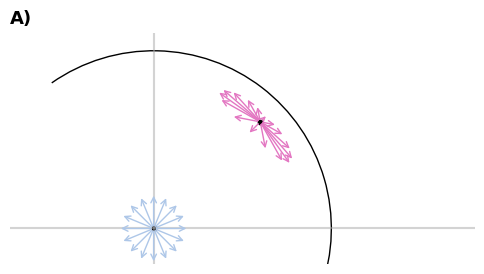

In [253]:
# Get the tab10 colors
all_colors = plt.get_cmap('tab20').colors  # tuple of 20 RGB colors
# The green color in tab10 is at index 1
colors = [tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])[i] for i in [0,7]]


R=1

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.left'] = False
mpl.rcParams['axes.spines.bottom'] = False
# circle and vertical ellipse

fig, ax = plt.subplots(figsize=(6, 3))

plot_circle(ax, 90, 1, theta1=-20, theta2=125)

sabbah = np.array([])
arrow_num = 22.5
input_stim = np.arange(0,360,arrow_num)

for g, x0 in enumerate([0,0.6]):
    z0=x0
    vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
    hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)
    
    if g in [5]:
        draw_ellipse(ax, vert_a, vert_b, color = colors[g])
        draw_ellipse(ax, hor_a, hor_b, color = colors[g])


    # point
    ax.scatter(x0, z0, s=10, c='k')

    arrow_len = 0.2

    final_arr = np.array([])
    color = colors[g]
    for idx, theta in enumerate(np.deg2rad(input_stim)):
        l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
        l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')

        resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
        final_arr = np.append(final_arr, resultant)
#         draw_arrow(ax, 0, 0, theta, arrow_len, color=color)

    final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 
    if x0==0:
#         draw_arrow(ax, 0, 0, theta, arrow_len, color='green')
        final_th = np.copy(input_stim)
        final_l = np.ones_like(final_th)*arrow_len
#     print((final_th-final_th[0])%360)
    for idx, arr in enumerate(final_th):
        draw_arrow(ax, x0, z0, np.deg2rad(arr), final_l[idx]/final_l.mean()*arrow_len, color=colors[g])
    sabbah = np.concatenate((sabbah, final_th[None,:]), axis=0) if sabbah.size else final_th[None,:]
# print(sabbah)



sabbah = np.concatenate((sabbah, final_th[None, :]), axis=0) if sabbah.size else final_th[None, :]

ax.text(-0, 1.1, 'A)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 13)

mpl.rcParams['axes.spines.left'] = True
mpl.rcParams['axes.spines.bottom'] = True
fig.savefig('R2Q1-images/Ecc_positions.jpg', bbox_inches = 'tight', dpi = 300)

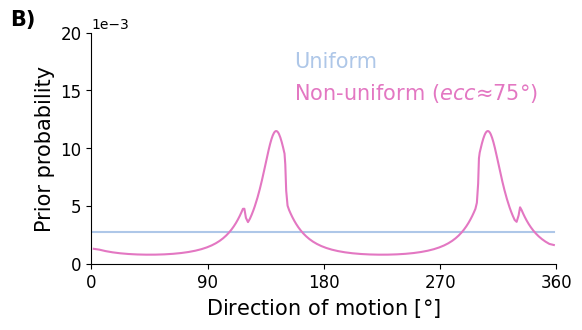

In [293]:
colors = [tuple(c for i, c in enumerate(all_colors) if i not in [0,2,4,5,6])[i] for i in [0,7]]

x0, z0=0.6, 0.6
stim_step = 2
d_stim = np.gradient(stim)
stim = np.arange(0,360,stim_step)
new_stim, new_delta, new_prior = eccentric_prior(x0,z0, stim_step)
# new_prior = new_prior/(new_prior*d_stim).sum()

fig, ax = plt.subplots(figsize = (6,3))
ax.tick_params(which='both', labelsize=12)
ax.plot(stim, new_prior*new_delta, color = colors[0], label = 'Uniform')
# ax.plot(new_stim, new_prior, color = colors[1], \
#         label = f'Non-uniform ($ecc\u2248{np.around(2*2*np.rad2deg(np.arcsin(0.6))/10)*5:.0f}\degree$)')

ax.plot(new_stim, new_prior, color = colors[1], \
        label = f'Non-uniform ($ecc\u2248{np.around(2*2*np.rad2deg(np.arcsin(0.6))/10)*5:.0f}\degree$)')


ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, -3))
ax.set_xticks(np.arange(0, 361, 90), size = 15)
ax.set_yticks(np.arange(0, 0.021, 0.005), size = 15)

ax.set_xlim(0, 360)
# ax.set_ylim(0, 0.008)

ax.text(-0.175, 1.1, 'B)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)

ax.set_xlabel(r'Direction of motion [$\degree$]', size =15)
ax.set_ylabel(r'Prior probability', size = 15)

ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 15)

fig.savefig('R2Q1-images/Ecc_prior.jpg', bbox_inches = 'tight', dpi = 300)

In [294]:
1/360

0.002777777777777778

In [7]:
quad_pair_tcs = data_dict['all_quad_tc'][[s_quad_idx, w_quad_idx]]
# quad_pair_ssis = nparray([[ssiMod.MC_SSI_w_PRIOR(stim, width_quad, new_prior) for width_quad in quad_type]\
#                            for quad_type in quad_pair_tcs])
from tqdm.notebook import tqdm
blocks = np.copy(quad_pair_tcs).reshape(-1, 4, 180)

results = [
    ssiMod.MC_SSI_w_PRIOR(stim, block, new_prior)
    for block in tqdm(blocks, total=np.product(blocks.shape[:1]))
]

quad_pair_ssis = np.array(results).reshape(2, 56, *results[0].shape)

  0%|          | 0/112 [00:00<?, ?it/s]

In [13]:
np.savez('R2Q1_nonunif_prior.npz', stim=stim, d_stim = d_stim, quad_idx=[s_quad_idx, w_quad_idx], \
                           quad_pair_tcs = quad_pair_tcs, new_prior = new_prior,
                           x0=x0,z0=z0, quad_pair_ssis = quad_pair_ssis)

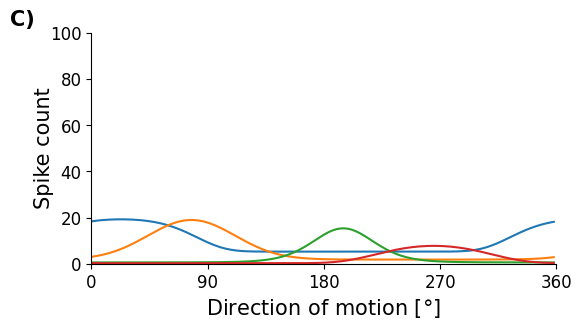

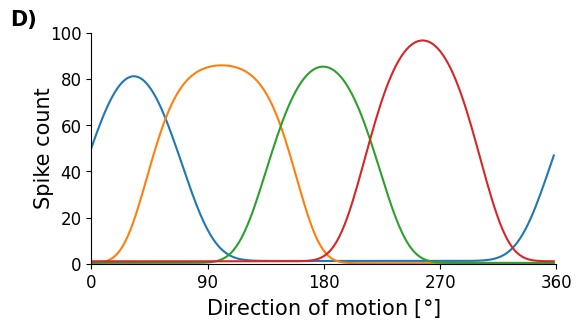

In [297]:
# First figure
fig, ax = plt.subplots(figsize =(6,3))
ax.tick_params(which = 'both', labelsize = 12)
ax.plot(stim, data_dict['all_quad_tc'][w_quad_idx, bio_idx].T)
ax.set_xticks(np.arange(0,361,90))
ax.set_xlim(0,360)
ax.set_ylim(0, 100)
ax.yaxis.set_label_coords(-0.08, 0.5)
ax.set_xlabel(r'Direction of motion [$\degree$]', size = 15)
ax.set_ylabel(r'Spike count', size = 15)
ax.text(-0.175, 1.1, 'C)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)
fig.savefig(f'R2Q1-images/Quad_{w_quad_idx}.jpg', bbox_inches = 'tight', dpi = 300)


# Second figure
fig, ax = plt.subplots(figsize =(6,3))
ax.tick_params(which = 'both', labelsize = 12)
ax.plot(stim, data_dict['all_quad_tc'][s_quad_idx, bio_idx].T)
ax.set_xticks(np.arange(0,361,90))
ax.set_xlim(0,360)
ax.set_ylim(0, 100)
ax.yaxis.set_label_coords(-0.08, 0.5)
ax.set_xlabel(r'Direction of motion [$\degree$]', size = 15)
ax.set_ylabel(r'Spike count', size = 15)
ax.text(-0.175, 1.1, 'D)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)
fig.savefig(f'R2Q1-images/Quad_{s_quad_idx}.jpg', bbox_inches = 'tight', dpi = 300)


0.35132169727467755


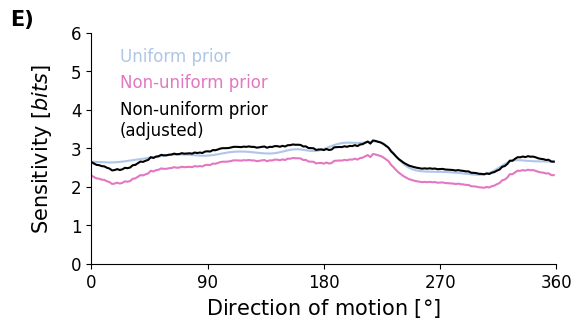

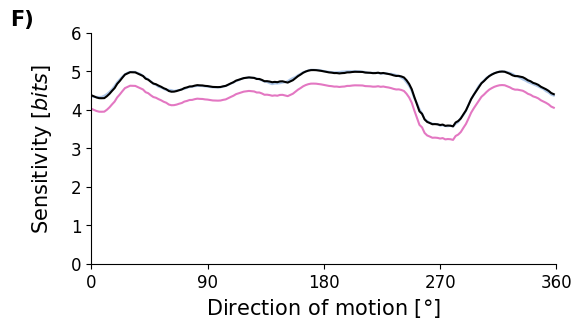

In [246]:
delta_ssi = np.log2(360)-(-np.sum(new_prior*d_stim*np.log2(new_prior)))
print(delta_ssi)
fig, ax = plt.subplots(figsize = (6,3))
ax.plot(stim, data_dict['all_ssis'][w_quad_idx, bio_idx], color = colors[0], label = 'Uniform prior')
ax.plot(stim, quad_pair_ssis[1, bio_idx], color = colors[1], label = 'Non-uniform prior')
ax.plot(stim, quad_pair_ssis[1, bio_idx]+delta_ssi, color  ='k', label = 'Non-uniform prior\n(adjusted)')
ax.set_xticks(np.arange(0,361,90))
ax.set_xlim(0,360)
ax.set_ylim(0,6)
ax.yaxis.set_label_coords(-0.08, 0.5)
ax.tick_params(which='both', labelsize = 12)
ax.set_xlabel(r'Direction of motion [$\degree$]', size = 15)
ax.set_ylabel(r'Sensitivity [$bits$]', size =15)
ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 12)
ax.text(-0.175, 1.1, 'E)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)

fig.savefig(f'R2Q1-images/SSI_Q{w_quad_idx}.jpg', bbox_inches = 'tight', dpi = 300)


fig, ax = plt.subplots(figsize = (6,3))
ax.plot(stim, data_dict['all_ssis'][s_quad_idx, bio_idx], color = colors[0], label = 'Uniform prior')
ax.plot(stim, quad_pair_ssis[0, bio_idx], color = colors[1], label = 'Non-uniform prior')
ax.plot(stim, quad_pair_ssis[0, bio_idx]+delta_ssi, color = 'k', label = 'Non-uniform prior\n(adjusted)')

ax.set_xticks(np.arange(0,361,90))
ax.set_xlim(0,360)
ax.set_ylim(0,6)
ax.yaxis.set_label_coords(-0.08, 0.5)
ax.tick_params(which='both', labelsize = 12)
ax.set_xlabel(r'Direction of motion [$\degree$]', size = 15)
ax.set_ylabel(r'Sensitivity [$bits$]', size =15)
# ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 12, loc = 'lower right')
ax.text(-0.175, 1.1, 'F)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)
fig.savefig(f'R2Q1-images/SSI_Q{s_quad_idx}.jpg', bbox_inches = 'tight', dpi = 300)


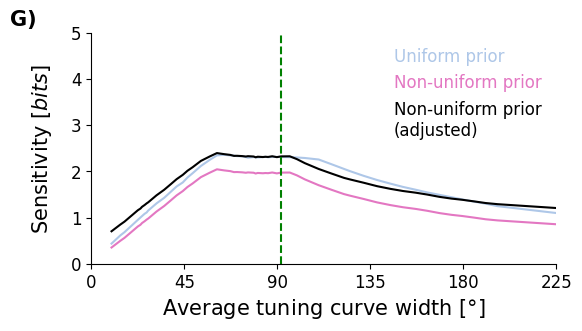

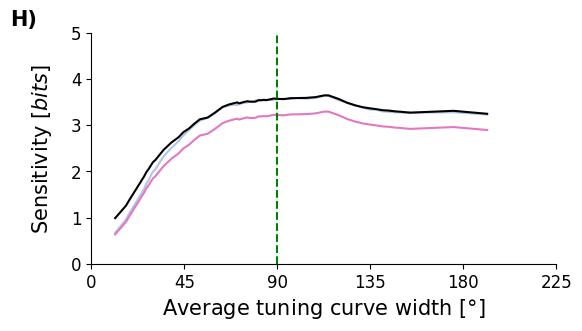

In [202]:
fig, ax = plt.subplots(figsize = (6,3))
ax.plot(data_dict['all_quad_fwhm'][w_quad_idx].mean(axis=1), data_dict['all_ssis'][w_quad_idx].min(axis=1),\
       color = colors[0], label = 'Uniform prior')
ax.plot(data_dict['all_quad_fwhm'][w_quad_idx].mean(axis=1), quad_pair_ssis[1].min(axis=1),\
       color = colors[1], label = 'Non-uniform prior')
ax.plot(data_dict['all_quad_fwhm'][w_quad_idx].mean(axis=1), quad_pair_ssis[1].min(axis=1)+delta_ssi,\
       color = 'k', label = 'Non-uniform prior\n(adjusted)')

# ax.plot(data_dict['all_quad_fwhm'][w_quad_idx].mean(axis=1), data_dict['all_ssis'][w_quad_idx].mean(axis=1), \
#        color = 'tab:blue')
# ax.plot(data_dict['all_quad_fwhm'][w_quad_idx].mean(axis=1), quad_pair_ssis[1].mean(axis=1), \
#        color = 'tab:orange')
# ax.plot(data_dict['all_quad_fwhm'][w_quad_idx].mean(axis=1), quad_pair_ssis[1].mean(axis=1)+delta_ssi,\
#        color  = 'tab:green')


ax.axvline(data_dict['all_quad_fwhm'][w_quad_idx, bio_idx].mean(), linestyle='dashed', color = 'green')
ax.set_xticks(np.arange(0,226,45))
ax.set_xlim(0,225)
ax.set_ylim(0,5)
ax.yaxis.set_label_coords(-0.08, 0.5)
ax.tick_params(which='both', labelsize = 12)
ax.set_xlabel(r'Average tuning curve width [$\degree$]', size = 15)
ax.set_ylabel(r'Sensitivity [$bits$]', size =15)
ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 12)
ax.text(-0.175, 1.1, 'G)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)
fig.savefig(f'R2Q1-images/MinSSI_Q{w_quad_idx}.jpg', bbox_inches = 'tight', dpi = 300)



fig, ax = plt.subplots(figsize = (6,3))
ax.plot(data_dict['all_quad_fwhm'][s_quad_idx].mean(axis=1), data_dict['all_ssis'][s_quad_idx].min(axis=1), \
       color = colors[0])
ax.plot(data_dict['all_quad_fwhm'][s_quad_idx].mean(axis=1), quad_pair_ssis[0].min(axis=1), \
       color = colors[1])
ax.plot(data_dict['all_quad_fwhm'][s_quad_idx].mean(axis=1), quad_pair_ssis[0].min(axis=1)+delta_ssi, \
       color = 'k')

# ax.plot(data_dict['all_quad_fwhm'][s_quad_idx].mean(axis=1), data_dict['all_ssis'][s_quad_idx].mean(axis=1), \
#        color = 'tab:blue')
# ax.plot(data_dict['all_quad_fwhm'][s_quad_idx].mean(axis=1), quad_pair_ssis[0].mean(axis=1), \
#        color = 'tab:orange')
# ax.plot(data_dict['all_quad_fwhm'][s_quad_idx].mean(axis=1), quad_pair_ssis[0].mean(axis=1)+delta_ssi,\
#        color= 'tab:green')

ax.axvline(data_dict['all_quad_fwhm'][s_quad_idx, bio_idx].mean(), linestyle='dashed', color = 'green')
ax.set_xticks(np.arange(0,226,45))
ax.set_xlim(0,225)
ax.set_ylim(0,5)
ax.yaxis.set_label_coords(-0.08, 0.5)
ax.tick_params(which='both', labelsize = 12)
ax.set_xlabel(r'Average tuning curve width [$\degree$]', size = 15)
ax.set_ylabel(r'Sensitivity [$bits$]', size =15)
# ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, fontsize = 12, loc = 'lower right')
ax.text(-0.175, 1.1, 'H)', ha='left', va='top', transform=ax.transAxes, fontweight='bold', fontsize = 15)
fig.savefig(f'R2Q1-images/MinSSI_Q{s_quad_idx}.jpg', bbox_inches = 'tight', dpi = 300)
